Dimensões originais: (118036, 39)

Tipos de dados:
category    25
category     9
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

Percentual de valores ausentes por variável:
CAPITAL - indica se é município da capital                                                                                                                                                                                                                 0.0
B01001A - Qual é o seu sexo?                                                                                                                                                                                                                               0.0
IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS                                                                                                                                                                                                               0.0
B01002 

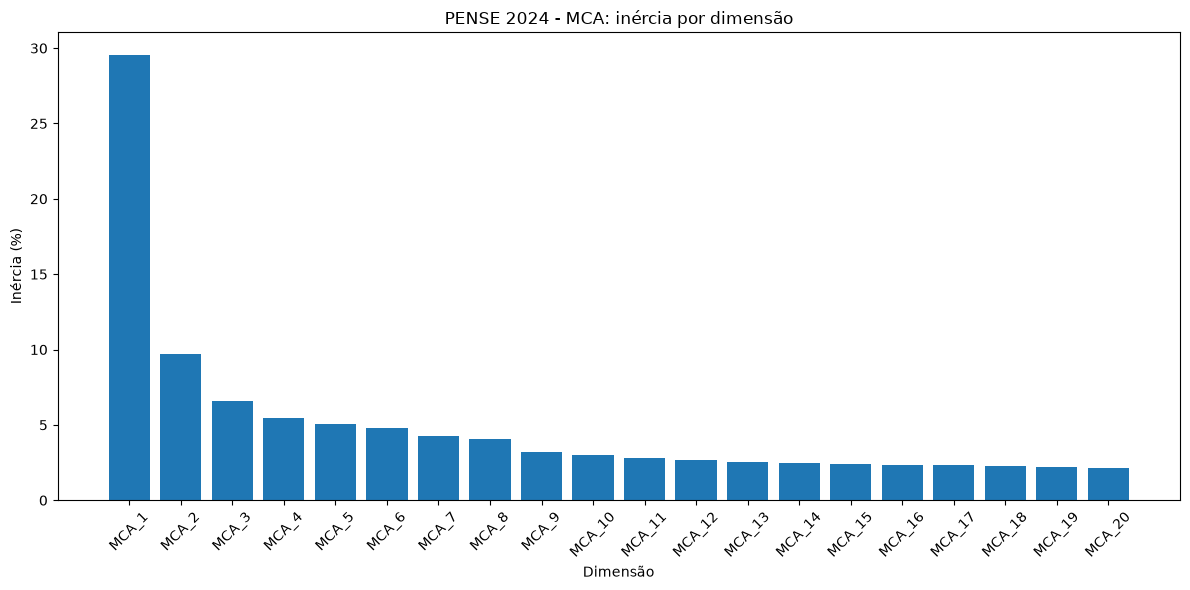

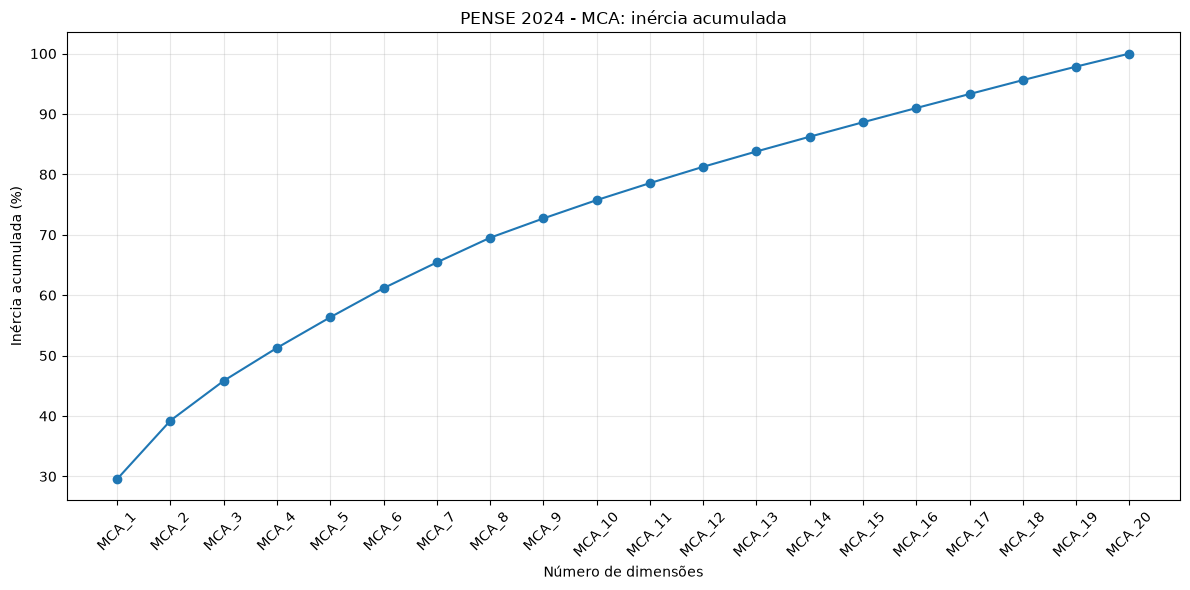


========== RESUMO DO MCA ==========
Registros: 118036
Variáveis utilizadas: 39
Dimensões produzidas: 20
Arquivo de coordenadas: /Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/08_PENSE2024_MCA_COORDENADAS.feather
Nenhum gráfico ou tabela de inércia foi salvo em arquivo.


In [15]:
# ============================================================
# PENSE 2024 - REDUÇÃO DE DIMENSIONALIDADE COM MCA
# Multiple Correspondence Analysis
#
# Saídas:
#   1. Exibe os gráficos na área de resultados do VS Code.
#   2. Salva APENAS o arquivo Feather com as coordenadas do MCA,
#      para uso posterior em algoritmos como K-means.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import prince

# ------------------------------------------------------------
# 1. CAMINHOS
# ------------------------------------------------------------

arquivo = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"
)

# O único arquivo de saída será salvo na mesma pasta do arquivo
# original, com nome começando por "08".
arquivo_coordenadas = arquivo.parent / "08_PENSE2024_MCA_COORDENADAS.feather"

# ------------------------------------------------------------
# 2. CARREGAR A BASE
# ------------------------------------------------------------

df = pd.read_feather(arquivo)

print("Dimensões originais:", df.shape)
print("\nTipos de dados:")
print(df.dtypes.value_counts())

# Guardar o índice original para manter a correspondência
# entre cada adolescente e suas coordenadas MCA.
indice_original = df.index.copy()

# ------------------------------------------------------------
# 3. PREPARAR AS VARIÁVEIS CATEGÓRICAS
# ------------------------------------------------------------

X = df.copy()

# Converter as colunas em texto e remover espaços extras.
for coluna in X.columns:
    X[coluna] = X[coluna].astype("string").str.strip()

# Tratar strings vazias como valores ausentes.
X = X.replace(r"^\s*$", pd.NA, regex=True)

print("\nPercentual de valores ausentes por variável:")
print((X.isna().mean() * 100).round(2).sort_values(ascending=False))

# Criar uma categoria explícita para valores ausentes.
X = X.fillna("Não informado")

# ------------------------------------------------------------
# 4. REMOVER VARIÁVEIS SEM VARIAÇÃO
# ------------------------------------------------------------

variaveis_constantes = [
    coluna for coluna in X.columns
    if X[coluna].nunique() <= 1
]

print("\nVariáveis constantes removidas:")
print(variaveis_constantes)

X = X.drop(columns=variaveis_constantes)

# IMPORTANTE:
# Se existirem identificadores, códigos de aluno ou variáveis
# administrativas, avalie removê-los antes do MCA.
# Exemplo:
# colunas_excluir = ["ID_ALUNO", "CODIGO_ESCOLA"]
# X = X.drop(columns=colunas_excluir, errors="ignore")

print("\nDimensões após a preparação:", X.shape)

# ------------------------------------------------------------
# 5. EXECUTAR O MCA
# ------------------------------------------------------------

n_dimensoes = min(20, X.shape[1])

mca = prince.MCA(
    n_components=n_dimensoes,
    n_iter=10,
    random_state=42
)

# Ajustar o MCA. Usamos fit() e calculamos as coordenadas
# explicitamente para contornar incompatibilidades de tipos
# observadas em algumas versões de Prince/pandas.
mca.fit(X)

A = mca._prepare(X)
A_array = A.to_numpy(dtype=np.float64)

massas = np.asarray(mca.col_masses_, dtype=np.float64)
V = np.asarray(mca.svd_.V, dtype=np.float64)

# Coordenadas das observações nas dimensões MCA selecionadas.
A_normalizada = A_array / A_array.sum(axis=1, keepdims=True)
V_ponderada = V.T * (massas ** -0.5)[:, None]
coordenadas_array = A_normalizada @ V_ponderada

coordenadas = pd.DataFrame(
    coordenadas_array[:, :n_dimensoes],
    columns=[f"MCA_{i+1}" for i in range(min(n_dimensoes, coordenadas_array.shape[1]))],
    index=indice_original
)

print("\nMCA concluído!")
print("Dimensões das coordenadas:", coordenadas.shape)

# ------------------------------------------------------------
# 6. SALVAR O ÚNICO ARQUIVO DE SAÍDA
# ------------------------------------------------------------

# O índice original é gravado como coluna para manter a
# identificação dos registros no arquivo de coordenadas.
coordenadas.reset_index(names="indice_original").to_feather(
    arquivo_coordenadas
)

print("\nÚnico arquivo salvo:")
print(arquivo_coordenadas)

# ------------------------------------------------------------
# 7. PREPARAR A TABELA DE INÉRCIA (SEM SALVAR EM ARQUIVO)
# ------------------------------------------------------------

autovalores = np.asarray(mca.eigenvalues_, dtype=float)

inercia = pd.DataFrame({
    "Dimensao": [f"MCA_{i+1}" for i in range(len(autovalores))],
    "Autovalor": autovalores,
    # Percentual relativo às dimensões extraídas pelo modelo.
    "Inercia_percentual": autovalores / autovalores.sum() * 100
})

inercia["Inercia_acumulada_percentual"] = (
    inercia["Inercia_percentual"].cumsum()
)

print("\nInércia por dimensão (não será salva em arquivo):")
print(inercia.round(3).to_string(index=False))

# ------------------------------------------------------------
# 8. GRÁFICO DA INÉRCIA POR DIMENSÃO
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))
plt.bar(inercia["Dimensao"], inercia["Inercia_percentual"])
plt.xlabel("Dimensão")
plt.ylabel("Inércia (%)")
plt.title("PENSE 2024 - MCA: inércia por dimensão")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. GRÁFICO DA INÉRCIA ACUMULADA
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))
plt.plot(
    inercia["Dimensao"],
    inercia["Inercia_acumulada_percentual"],
    marker="o"
)
plt.xlabel("Número de dimensões")
plt.ylabel("Inércia acumulada (%)")
plt.title("PENSE 2024 - MCA: inércia acumulada")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. RESUMO FINAL
# ------------------------------------------------------------

print("\n========== RESUMO DO MCA ==========")
print("Registros:", X.shape[0])
print("Variáveis utilizadas:", X.shape[1])
print("Dimensões produzidas:", coordenadas.shape[1])
print("Arquivo de coordenadas:", arquivo_coordenadas)
print("Nenhum gráfico ou tabela de inércia foi salvo em arquivo.")
print("===================================")
